# 03. Lọc biến cho model churn

## Quyết định đã chốt ở notebook 02 (Task 2)

| Tham số | Giá trị | Ý nghĩa |
| :--- | :--- | :--- |
| `W` | 12 tháng | churn = khách không có đơn hợp lệ trong `[t, t + 12 tháng)` |
| `L` | 3 năm | chỉ xét khách có ít nhất 1 đơn hợp lệ trong `[t − 3 năm, t)` |
| Train | 2019-01, 2019-07, 2020-01 | dùng để fit và lọc biến |
| Validation | 2021-01 | chọn model, permutation importance |
| Test | 2022-01 | **không mở trong notebook này** |

- Đơn hợp lệ: khác `cancelled`, `created` (`clean.py`, R1).
- Nhãn nên hiểu là "không mua trong 12 tháng tới": 39% khách bị gán churn quay lại sau đó (notebook 02, mục 1).
- Cùng một khách xuất hiện ở nhiều mốc train, nên không dùng k-fold ngẫu nhiên.
- Mốc cần vượt: recency đứng riêng đạt AUC ≈ 0,61 ở mốc validation.

Các giá trị lấy từ `ml/src/config.py`.

In [1]:
import sys
sys.path.insert(0, "../src")
import config
print(config.W_MONTHS, config.L_YEARS, [d.date() for d in config.TRAIN_CUTOFFS], config.VALID_CUTOFF.date(), config.TEST_CUTOFF.date())

12 3 [datetime.date(2019, 1, 1), datetime.date(2019, 7, 1), datetime.date(2020, 1, 1)] 2021-01-01 2022-01-01


In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, json
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score, average_precision_score
import lightgbm as lgb
import viz
from features import FEATURES, CATEGORICAL
from config import TRAIN_CUTOFFS, VALID_CUTOFF

RNG = 0
names = [f"{c:%Y-%m}" for c in TRAIN_CUTOFFS]
tr = {n: pd.read_parquet(f"../data/interim/snap_{n}.parquet") for n in names}
va = pd.read_parquet(f"../data/interim/snap_{VALID_CUTOFF:%Y-%m}.parquet")
# Cùng bộ category ở mọi snapshot để LightGBM không lệch mã
for c in CATEGORICAL:
    cats = sorted(set().union(*[set(d[c].dropna().astype(str)) for d in [*tr.values(), va]]))
    for d in [*tr.values(), va]:
        d[c] = pd.Categorical(d[c].astype(str).where(d[c].notna()), categories=cats)
X_COLS = [c for c in FEATURES]
TRAIN = pd.concat(tr.values(), ignore_index=True)
print(TRAIN.shape, va.shape, len(X_COLS), "feature")
print("Train churn:", TRAIN.churn.mean().round(3), "| Valid churn:", va.churn.mean().round(3))

(182184, 39) (52771, 39) 36 feature
Train churn: 0.676 | Valid churn: 0.675


## Bước 1. Độ liên quan với nhãn

Mỗi biến được chấm **riêng lẻ** trên tập train gộp ba mốc:

- **AUC đứng riêng**: dùng chính biến làm điểm dự đoán churn (lấy `max(AUC, 1 − AUC)` để không phụ thuộc chiều). 0,5 = không phân biệt được gì. Chỉ tính cho biến số; thiếu giá trị thì điền trung vị.
- **Mutual information (MI)**: đo mọi quan hệ (cả phi tuyến, cả biến phân loại) giữa biến và nhãn. Tính trên mẫu 40.000 dòng để nhanh.

**Quy tắc loại:** AUC đứng riêng trong 0,5 ± 0,01 **và** MI < 0,001. Cần cả hai điều kiện vì một biến có thể vô dụng khi đứng riêng nhưng có ích khi kết hợp, và AUC không thấy được quan hệ hình chữ U.

In [3]:
y = TRAIN.churn.values
num = [c for c in X_COLS if c not in CATEGORICAL]
rows = []
for c in X_COLS:
    s = TRAIN[c]
    if c in CATEGORICAL:
        auc = np.nan
    else:
        v = s.fillna(s.median()).values
        a = roc_auc_score(y, v); auc = max(a, 1 - a)
    rows.append((c, FEATURES[c][0], auc))
rel = pd.DataFrame(rows, columns=["feature", "group", "auc"]).set_index("feature")

samp = TRAIN.sample(40000, random_state=RNG)
Xm = samp[X_COLS].copy()
for c in CATEGORICAL: Xm[c] = Xm[c].cat.codes
Xm = Xm.fillna(Xm.median())
rel["mi"] = mutual_info_classif(Xm, samp.churn, discrete_features=[c in CATEGORICAL for c in X_COLS], random_state=RNG)
rel["n_missing_pct"] = (TRAIN[X_COLS].isna().mean() * 100).round(1)
rel["drop_step1"] = (rel.auc.fillna(0.5).sub(0.5).abs() < 0.01) & (rel.mi < 0.001)
rel.sort_values("mi", ascending=False).round(4)

,group,auc,mi,n_missing_pct,drop_step1
feature,,,,,
monetary,RFM,0.7437,0.1056,0.0,False
std_gap_days,Nhịp mua,0.6253,0.0996,28.3,False
mean_gap_days,Nhịp mua,0.6854,0.0976,15.4,False
frequency,RFM,0.7607,0.0940,0.0,False
active_years,Nhịp mua,0.7443,0.0873,0.0,False
promo_share,Hành vi,0.5205,0.0769,0.0,False
mobile_share,Hành vi,0.5095,0.0760,0.0,False
avg_installments,Hành vi,0.5384,0.0759,0.0,False
installment_share,Hành vi,0.5151,0.0756,0.0,False


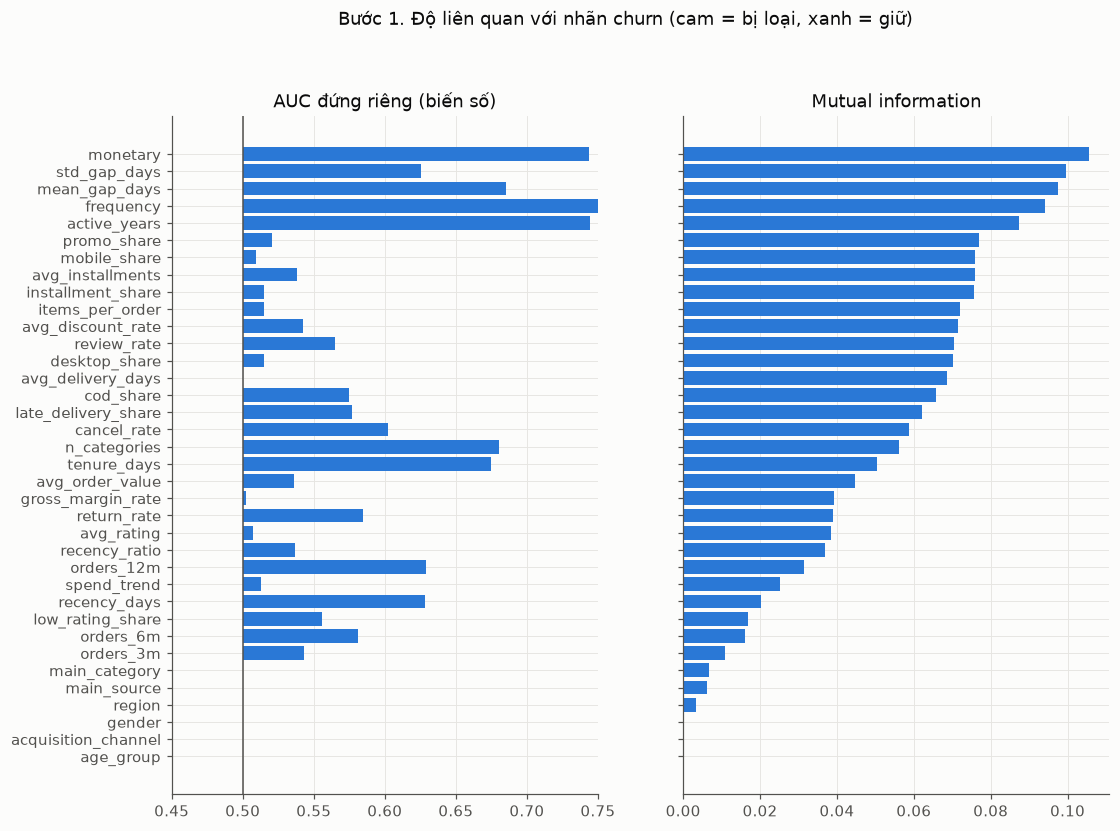

Bị loại ở bước 1: ['gender', 'age_group', 'acquisition_channel']


In [4]:
o = rel.sort_values("mi")
fig, ax = plt.subplots(1, 2, figsize=(11, 8), sharey=True)
col = [viz.C[1] if d else viz.C[0] for d in o.drop_step1]
ax[0].barh(o.index, o.auc.fillna(0.5) - 0.5, left=0.5, color=col); ax[0].axvline(0.5, color=viz.INK2, lw=1)
ax[0].set_xlim(0.45, 0.75); ax[0].set_title("AUC đứng riêng (biến số)")
ax[1].barh(o.index, o.mi, color=col); ax[1].set_title("Mutual information")
fig.suptitle("Bước 1. Độ liên quan với nhãn churn (cam = bị loại, xanh = giữ)", y=1.0)
viz.save(fig, "03_relevance"); plt.show()
print("Bị loại ở bước 1:", list(rel.index[rel.drop_step1]))

## Bước 2. Loại biến trùng lặp (tương quan Spearman)

Hai biến tương quan |ρ| > 0,9 gần như mang cùng một thông tin. Giữ cả hai không giúp model dự báo tốt hơn, mà còn làm importance bị chia đôi và khó diễn giải. Cách làm: gom cụm phân cấp (liên kết trung bình) với khoảng cách `1 − |ρ|`, cắt ở 0,1, mỗi cụm **giữ biến có liên quan với nhãn nhất** (xếp theo MI, vì dùng được cho mọi loại biến). Dùng Spearman vì nhiều biến lệch phải mạnh. Biến phân loại không tham gia bước này.

     bị loại giữ thay bằng  Spearman ρ
active_years     frequency       0.951


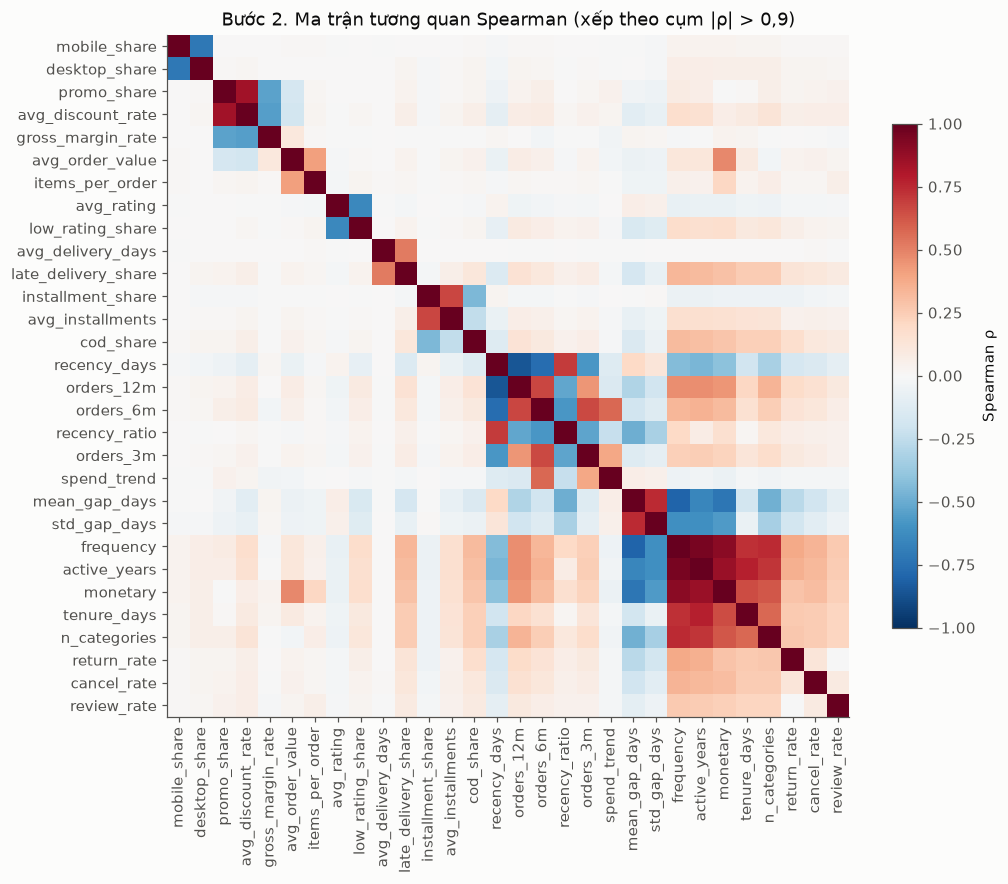

In [5]:
keep1 = [c for c in num if not rel.loc[c, "drop_step1"]]
rho = TRAIN[keep1].corr(method="spearman").fillna(0)
dist = 1 - rho.abs().values; np.fill_diagonal(dist, 0)
Z = linkage(squareform(dist, checks=False), "average")
cl = pd.Series(fcluster(Z, t=0.1, criterion="distance"), index=keep1)
step2 = []
for k, members in cl.groupby(cl):
    members = list(members.index)
    if len(members) > 1:
        best = max(members, key=lambda c: rel.loc[c, "mi"])
        for c in members:
            if c != best:
                step2.append((c, best, rho.loc[c, best]))
dup = pd.DataFrame(step2, columns=["bị loại", "giữ thay bằng", "Spearman ρ"]).round(3)
print(dup.to_string(index=False) if len(dup) else "Không có cụm nào")
order = rho.index[np.argsort(cl.values)]
fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(rho.loc[order, order], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90); ax.set_yticks(range(len(order)), order); ax.grid(False)
fig.colorbar(im, shrink=0.7, label="Spearman ρ"); ax.set_title("Bước 2. Ma trận tương quan Spearman (xếp theo cụm |ρ| > 0,9)")
viz.save(fig, "03_corr_heatmap"); plt.show()

## Bước 3. Permutation importance của LightGBM trên validation

**Ý tưởng:** train LightGBM trên tập train, rồi trên validation xáo trộn ngẫu nhiên một cột và đo PR-AUC giảm bao nhiêu. Giảm nhiều = model dựa vào cột đó thật; giảm ≈ 0 = bỏ đi không mất gì. Làm trên validation (không phải train) để không thưởng cho biến chỉ giúp model học thuộc.

- Lặp 15 lần xáo trộn, lấy trung bình và **khoảng tin cậy 95%** (± 1,96 × sai số chuẩn).
- **Quy tắc loại:** khoảng tin cậy chứa 0.
- Dùng PR-AUC (`average_precision`) vì đây là thước đo chính của đồ án. LightGBM tham số cố định, đủ nông để không học thuộc (tinh chỉnh ở Task 6).

In [6]:
PARAMS = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=100,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
              random_state=RNG, verbose=-1, n_jobs=-1)
keep2 = [c for c in keep1 if c not in set(dup["bị loại"])] + CATEGORICAL
keep2 = [c for c in keep2 if not rel.loc[c, "drop_step1"]]
print("Còn lại sau bước 1-2:", len(keep2), "biến")

def perm_importance(model, df, cols, n_rep=15, seed=RNG):
    r = np.random.RandomState(seed)
    base = average_precision_score(df.churn, model.predict_proba(df[cols])[:, 1])
    out = {}
    for c in cols:
        d = df[cols].copy(); drops = []
        for _ in range(n_rep):
            d[c] = d[c].values[r.permutation(len(d))]
            drops.append(base - average_precision_score(df.churn, model.predict_proba(d)[:, 1]))
        out[c] = (np.mean(drops), 1.96 * np.std(drops, ddof=1) / np.sqrt(n_rep))
    return base, pd.DataFrame(out, index=["mean", "ci"]).T

m_all = lgb.LGBMClassifier(**PARAMS).fit(TRAIN[keep2], TRAIN.churn)
base, pi = perm_importance(m_all, va, keep2)
pi["drop_step3"] = (pi["mean"] - pi.ci) <= 0
print("PR-AUC validation (mọi biến còn lại):", round(base, 4), "| ROC-AUC:", round(roc_auc_score(va.churn, m_all.predict_proba(va[keep2])[:, 1]), 4))
pi.sort_values("mean", ascending=False).round(5)

Còn lại sau bước 1-2: 32 biến


PR-AUC validation (mọi biến còn lại): 0.8585 | ROC-AUC: 0.7582


,mean,ci,drop_step3
frequency,0.09250,0.00070,False
cancel_rate,0.00364,0.00020,False
mean_gap_days,0.00219,0.00033,False
monetary,0.00174,0.00022,False
std_gap_days,0.00124,0.00021,False
main_source,0.00053,0.00009,False
region,0.00031,0.00005,False
avg_installments,0.00028,0.00004,False
main_category,0.00021,0.00005,False
recency_days,0.00017,0.00010,False


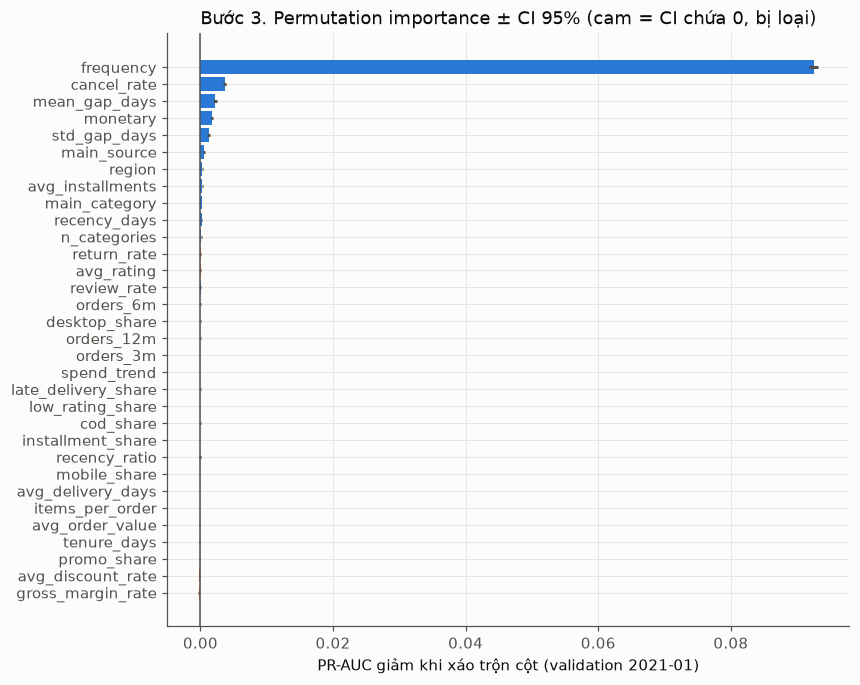

In [7]:
o = pi.sort_values("mean")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(o.index, o["mean"], xerr=o.ci, color=[viz.C[1] if d else viz.C[0] for d in o.drop_step3], ecolor=viz.INK2)
ax.axvline(0, color=viz.INK2, lw=1); ax.set_xlabel("PR-AUC giảm khi xáo trộn cột (validation 2021-01)")
ax.set_title("Bước 3. Permutation importance ± CI 95% (cam = CI chứa 0, bị loại)")
viz.save(fig, "03_perm_importance"); plt.show()

## Bước 4. Độ ổn định qua các mốc cắt train

Một biến chỉ quan trọng ở một mốc có thể là tín hiệu của riêng giai đoạn đó (dữ liệu đổi phân phối sau 2018), không đáng tin để đưa vào model. Cách kiểm: với mỗi mốc train, fit LightGBM **chỉ trên mốc đó**, đo permutation importance trên **validation**. Mỗi biến có 3 giá trị; so sánh thứ hạng và dấu.

Biến bị **ghi chú nghi ngờ** nếu importance dương (CI lớn hơn 0) ở ít hơn 3/3 mốc. Đây là cảnh báo để người đọc cân nhắc, không tự động loại (chỉ loại nếu cũng đã vô dụng ở bước 3).

In [8]:
surv3 = list(pi.index[~pi.drop_step3])
stab = {}
for n, d in tr.items():
    m = lgb.LGBMClassifier(**PARAMS).fit(d[surv3], d.churn)
    _, p = perm_importance(m, va, surv3, n_rep=8)
    stab[n] = p
stab_mean = pd.DataFrame({n: p["mean"] for n, p in stab.items()})
stab_pos = pd.DataFrame({n: (p["mean"] - p["ci"]) > 0 for n, p in stab.items()})
stab_mean["so_mốc_dương"] = stab_pos.sum(axis=1)
stab_rank = pd.DataFrame({n: p["mean"].rank(ascending=False) for n, p in stab.items()})
stab_mean["thứ_hạng_TB"] = stab_rank.mean(axis=1)
stab_mean["nghi_ngờ"] = stab_mean["so_mốc_dương"] < 3
stab_mean.sort_values("thứ_hạng_TB").round(5)

,2019-01,2019-07,2020-01,so_mốc_dương,thứ_hạng_TB,nghi_ngờ
frequency,0.09736,0.09556,0.10213,3,1.00000,False
mean_gap_days,0.00375,0.00289,0.00471,3,2.33333,False
cancel_rate,0.00371,0.00391,0.00383,3,2.66667,False
std_gap_days,0.00202,0.00255,0.00260,3,4.33333,False
monetary,0.00222,0.00172,0.00121,3,4.66667,False
main_source,0.00034,0.00065,0.00036,3,7.66667,False
region,0.00034,0.00025,0.00054,3,8.00000,False
recency_days,0.00064,0.00003,0.00060,2,8.00000,True
main_category,0.00029,0.00025,0.00040,3,8.33333,False
avg_installments,0.00035,0.00017,0.00014,3,8.66667,False


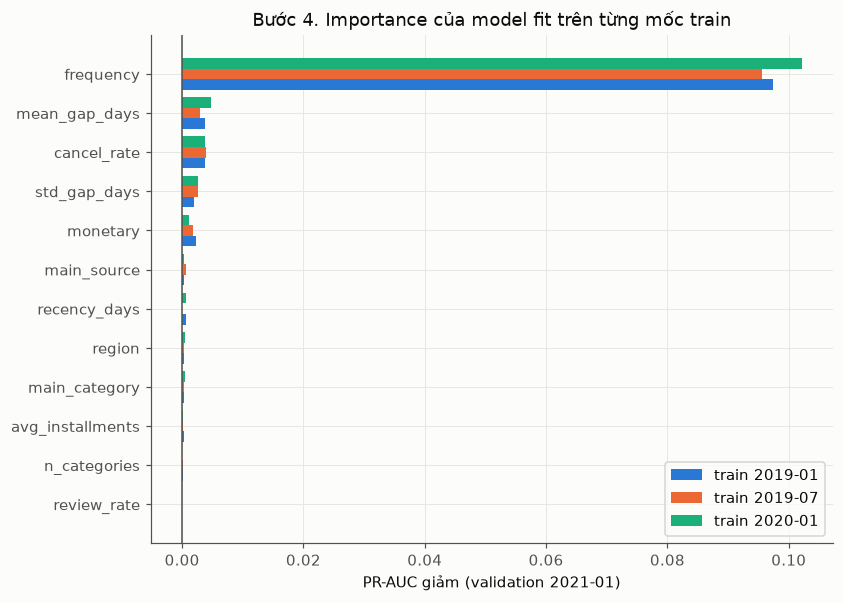

Nghi ngờ: ['review_rate', 'n_categories', 'recency_days']


In [9]:
o = stab_mean.sort_values("thứ_hạng_TB", ascending=False)
fig, ax = plt.subplots(figsize=(8, 6)); w = 0.27
for i, n in enumerate(names):
    ax.barh(np.arange(len(o)) + (i - 1) * w, o[n], height=w, color=viz.C[i], label=f"train {n}")
ax.set_yticks(range(len(o)), o.index); ax.axvline(0, color=viz.INK2, lw=1); ax.legend()
ax.set_xlabel("PR-AUC giảm (validation 2021-01)"); ax.set_title("Bước 4. Importance của model fit trên từng mốc train")
viz.save(fig, "03_stability"); plt.show()
print("Nghi ngờ:", list(o.index[o.nghi_ngờ]))

## Bảng kết quả: biến bị loại, ở bước nào, vì sao, và danh sách cuối

In [10]:
log = []
for c in X_COLS:
    r = rel.loc[c]
    if r.drop_step1:
        log.append((c, FEATURES[c][0], "1. Độ liên quan", (f"AUC đứng riêng {r.auc:.3f}, " if r.auc == r.auc else "biến phân loại, ") + f"MI {r.mi:.4f}: gần như không liên quan nhãn"))
for _, row in dup.iterrows():
    log.append((row["bị loại"], FEATURES[row["bị loại"]][0], "2. Tương quan", f"Spearman ρ = {row['Spearman ρ']:.2f} với {row['giữ thay bằng']} (giữ biến kia vì liên quan nhãn hơn)"))
for c in pi.index[pi.drop_step3]:
    log.append((c, FEATURES[c][0], "3. Permutation importance", f"PR-AUC giảm {pi.loc[c,'mean']:+.5f} ± {pi.loc[c,'ci']:.5f}: CI chứa 0"))
removed = pd.DataFrame(log, columns=["biến", "nhóm", "bị loại ở bước", "lý do"])
FINAL = list(surv3)
print(f"Bị loại {len(removed)} / {len(X_COLS)} biến; giữ {len(FINAL)}")
display(removed)
final_tbl = pd.DataFrame({
    "nhóm": [FEATURES[c][0] for c in FINAL],
    "PR-AUC giảm (validation)": [pi.loc[c, "mean"] for c in FINAL],
    "số mốc train ổn định (/3)": [int(stab_mean.loc[c, "so_mốc_dương"]) for c in FINAL],
    "ghi chú": ["nghi ngờ: không ổn định qua mốc cắt" if stab_mean.loc[c, "nghi_ngờ"] else "" for c in FINAL]}, index=FINAL
).sort_values("PR-AUC giảm (validation)", ascending=False).round(5)
final_tbl

Bị loại 24 / 36 biến; giữ 12


,biến,nhóm,bị loại ở bước,lý do
0,gender,Nhân khẩu học,1. Độ liên quan,"biến phân loại, MI 0.0001: gần như không liên ..."
1,age_group,Nhân khẩu học,1. Độ liên quan,"biến phân loại, MI 0.0001: gần như không liên ..."
2,acquisition_channel,Nhân khẩu học,1. Độ liên quan,"biến phân loại, MI 0.0001: gần như không liên ..."
3,active_years,Nhịp mua,2. Tương quan,Spearman ρ = 0.95 với frequency (giữ biến kia ...
4,tenure_days,RFM,3. Permutation importance,PR-AUC giảm -0.00012 ± 0.00006: CI chứa 0
5,avg_order_value,RFM,3. Permutation importance,PR-AUC giảm -0.00009 ± 0.00009: CI chứa 0
6,recency_ratio,Nhịp mua,3. Permutation importance,PR-AUC giảm -0.00005 ± 0.00011: CI chứa 0
7,orders_3m,Nhịp mua,3. Permutation importance,PR-AUC giảm -0.00000 ± 0.00000: CI chứa 0
8,orders_6m,Nhịp mua,3. Permutation importance,PR-AUC giảm +0.00001 ± 0.00001: CI chứa 0
9,orders_12m,Nhịp mua,3. Permutation importance,PR-AUC giảm +0.00001 ± 0.00001: CI chứa 0


,nhóm,PR-AUC giảm (validation),số mốc train ổn định (/3),ghi chú
frequency,RFM,0.09250,3,
cancel_rate,Hành vi,0.00364,3,
mean_gap_days,Nhịp mua,0.00219,3,
monetary,RFM,0.00174,3,
std_gap_days,Nhịp mua,0.00124,3,
main_source,Hành vi,0.00053,3,
region,Nhân khẩu học,0.00031,3,
avg_installments,Hành vi,0.00028,3,
main_category,Hành vi,0.00021,3,
recency_days,RFM,0.00017,2,nghi ngờ: không ổn định qua mốc cắt


In [11]:
# Kiểm tra nhanh: tập biến cuối không tệ hơn tập đầy đủ trên validation (chỉ để chắc việc lọc không làm hại)
def va_score(cols):
    m = lgb.LGBMClassifier(**PARAMS).fit(TRAIN[cols], TRAIN.churn); p = m.predict_proba(va[cols])[:, 1]
    return average_precision_score(va.churn, p), roc_auc_score(va.churn, p)
cmp = pd.DataFrame({f"đủ {len(X_COLS)} biến": va_score(X_COLS), f"sau lọc ({len(FINAL)} biến)": va_score(FINAL)}, index=["PR-AUC", "ROC-AUC"]).round(4)
print("Tỷ lệ churn validation (PR-AUC của dự đoán ngẫu nhiên):", round(va.churn.mean(), 3)); cmp

Tỷ lệ churn validation (PR-AUC của dự đoán ngẫu nhiên): 0.675


,đủ 36 biến,sau lọc (12 biến)
PR-AUC,0.8587,0.8595
ROC-AUC,0.7582,0.7586


In [12]:
from pathlib import Path
out = {"final_features": FINAL, "categorical": [c for c in FINAL if c in CATEGORICAL],
       "removed": removed.to_dict("records"), "suspect": list(stab_mean.index[stab_mean.nghi_ngờ])}
Path("../reports/churn_features.json").write_text(json.dumps(out, ensure_ascii=False, indent=1), encoding="utf8")

4387

## Nhận xét và giới hạn

- **Mọi nhóm biến chỉ còn lại ít đại diện.** `frequency` gần như một mình gánh model (PR-AUC giảm 0,0925 khi bị xáo trộn, gấp 25 lần biến đứng thứ hai). Nhóm nhịp mua đóng góp qua `mean_gap_days`, `std_gap_days`; nhóm hành vi chỉ còn `cancel_rate`, `avg_installments`, `main_source`, `main_category`, `n_categories`, `review_rate`; nhân khẩu học chỉ còn `region`. Đóng góp thật của từng nhóm sẽ đo bằng ablation ở Task 5.
- **Điểm yếu của permutation importance với biến tương quan:** nếu hai biến thay thế được cho nhau (ví dụ `orders_3m/6m/12m` và `frequency`), xáo trộn một biến không làm model tệ đi vì biến kia gánh thay, nên cả hai đều có vẻ "vô dụng". Vì vậy kết quả bước 3 được kiểm chứng bằng cách train lại với tập biến cuối: PR-AUC không giảm (xem bảng so sánh), tức là việc bỏ cả loạt cùng lúc không làm mất thông tin.
- **`cancel_rate` cần thận trọng khi diễn giải.** `order_status` là trạng thái cuối cùng (giới hạn đã ghi ở `features.py`), nên một phần tín hiệu của biến này có thể là rò rỉ nhẹ: đơn đặt trước mốc nhưng bị hủy sau mốc. Ablation ở Task 5 nên chạy thêm một bản không có `cancel_rate`.
- **Ba biến bị ghi chú nghi ngờ:** `recency_days`, `n_categories`, `review_rate` (không dương ở cả 3 mốc train). Giữ lại để Task 5 quyết định bằng ablation, vì đóng góp đều rất nhỏ.
- `recency_days` đứng riêng có AUC 0,63 nhưng importance thấp khi đã có `frequency` và `mean_gap_days`: recency đã được hai biến kia giải thích phần lớn.

## Sơ đồ giải thuật của model churn

Hình dưới dùng cho mục 2 của báo cáo. Bước train và hiệu chỉnh thực hiện ở Task 5–6.

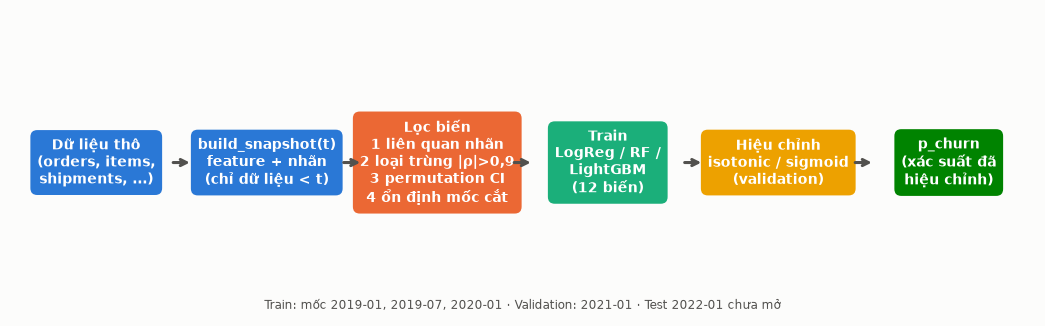

In [13]:
fig, ax = plt.subplots(figsize=(12, 3.6)); ax.axis("off"); ax.grid(False)
steps = [("Dữ liệu thô\n(orders, items,\nshipments, ...)", viz.C[0]),
         ("build_snapshot(t)\nfeature + nhãn\n(chỉ dữ liệu < t)", viz.C[0]),
         ("Lọc biến\n1 liên quan nhãn\n2 loại trùng |ρ|>0,9\n3 permutation CI\n4 ổn định mốc cắt", viz.C[1]),
         (f"Train\nLogReg / RF /\nLightGBM\n({len(FINAL)} biến)", viz.C[2]),
         ("Hiệu chỉnh\nisotonic / sigmoid\n(validation)", viz.C[3]),
         ("p_churn\n(xác suất đã\nhiệu chỉnh)", viz.C[5])]
for i, (txt, col) in enumerate(steps):
    x = i * 1.8
    ax.text(x, 0.5, txt, ha="center", va="center", fontsize=9, color="white", fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.5", fc=col, ec="none"))
    if i: ax.annotate("", xy=(x - 0.78, 0.5), xytext=(x - 1.02, 0.5), arrowprops=dict(arrowstyle="->", color=viz.INK2, lw=2))
ax.set_xlim(-0.9, 9.9); ax.set_ylim(0, 1)
ax.text(4.5, 0.02, "Train: mốc 2019-01, 2019-07, 2020-01 · Validation: 2021-01 · Test 2022-01 chưa mở", ha="center", fontsize=8, color=viz.INK2)
viz.save(fig, "03_churn_algorithm"); plt.show()